# Projeto Fase 6 — Comparação de Modelos de Visão Computacional
---

## Entrega 2
Nesta entrega serão comparadas três abordagens de Visão Computacional:

1. YOLOv5 adaptável desenvolvida na Entrega 1;
2. YOLOv5 padrão utilizando pesos pré-treinados;
3. CNN treinada do zero para classificação de imagens.

Os modelos serão analisados considerando:

- Facilidade de uso e integração;
- Desempenho apresentado;
- Tempo de treinamento ou customização;
- Tempo de inferência.

A YOLOv5 padrão será utilizada diretamente com seus pesos pré-treinados,
sem treinamento com o dataset deste projeto. Seus resultados serão
comparados com a YOLOv5 customizada na Entrega 1 e com uma CNN construída
e treinada do zero.

## Preparação do ambiente e do dataset

Nesta etapa são configurados o ambiente de execução, a YOLOv5 e o dataset
utilizado nos experimentos.

In [1]:
# Verificar GPU disponível no ambiente

import torch

print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU não disponível no momento.")

CUDA disponível: True
GPU: Tesla T4


In [2]:
# Clonar o repositório YOLOv5

!git clone https://github.com/ultralytics/yolov5.git

Cloning into 'yolov5'...
remote: Enumerating objects: 18756, done.
remote: Counting objects: 100% (314/314), done.
remote: Compressing objects: 100% (183/183), done.
remote: Total 18756 (delta 256), reused 131 (delta 131), pack-reused 18442 (from 4)
Receiving objects: 100% (18756/18756), 17.79 MiB | 19.81 MiB/s, done.
Resolving deltas: 100% (12759/12759), done.


In [3]:
# Acessar a pasta da YOLOv5

%cd /content/yolov5

# Instalar as dependências necessárias

!pip install -r requirements.txt -q

/content/yolov5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 75.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.0/90.0 kB 9.3 MB/s eta 0:00:00


In [5]:
# Descompactar o dataset diretamente em /content

import zipfile
import os

zip_path = "/content/dataset.zip"
destino = "/content"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(destino)

dataset_path = "/content/dataset"

print("Dataset descompactado com sucesso!")
print("\nConteúdo da pasta dataset:")
print(os.listdir(dataset_path))

Dataset descompactado com sucesso!

Conteúdo da pasta dataset:


FileNotFoundError: [Errno 2] No such file or directory: '/content/dataset'

In [6]:
# Verificar o que foi extraído em /content

import os

print("Conteúdo de /content:")

for item in os.listdir("/content"):
    print("-", item)

Conteúdo de /content:
- .config
- yolov5
- dataset.zip
- test
- train
- val
- sample_data


In [7]:
# Organizar as pastas do dataset

import os
import shutil

dataset_path = "/content/dataset"

# Criar a pasta principal
os.makedirs(dataset_path, exist_ok=True)

# Mover train, val e test
for pasta in ["train", "val", "test"]:
    origem = f"/content/{pasta}"
    destino = f"{dataset_path}/{pasta}"

    if os.path.exists(origem):
        shutil.move(origem, destino)

print("Dataset organizado com sucesso!")
print("\nConteúdo:")
print(os.listdir(dataset_path))

Dataset organizado com sucesso!

Conteúdo:
['test', 'train', 'val']


## YOLOv5 padrão com pesos pré-treinados

Nesta etapa, a YOLOv5 será utilizada diretamente com os pesos pré-treinados
`yolov5s.pt`, sem realizar treinamento com as imagens deste projeto.

O objetivo é observar o comportamento de um modelo genérico diante das
mesmas imagens utilizadas no projeto e posteriormente comparar seus
resultados com a YOLOv5 customizada na Entrega 1.

In [8]:
# YOLOv5 padrão - inferência nas imagens de teste

%cd /content/yolov5

!python detect.py \
    --weights yolov5s.pt \
    --img 640 \
    --source /content/dataset/test/images \
    --name yolo_padrao

/content/yolov5
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
detect: weights=['yolov5s.pt'], source=/content/dataset/test/images, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=yolo_padrao, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-553-g402e17dd Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)

100% 14.1M/14.1M [00:00<00:00, 282MB/s]

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gr

### Análise da YOLOv5 padrão

A YOLOv5 padrão foi utilizada diretamente com os pesos pré-treinados
`yolov5s.pt`, sem realizar treinamento com o dataset deste projeto.

Nas quatro imagens de gatos, o modelo identificou corretamente a classe
`cat`. Entretanto, nas quatro imagens de tênis, o modelo não realizou
nenhuma identificação correta, classificando os objetos como `kite`,
`cell phone` e `person`, além de não detectar nenhum objeto em uma das
imagens.

O resultado demonstra que um modelo pré-treinado pode apresentar bom
desempenho quando a classe desejada já está contemplada em seu treinamento
original. Entretanto, para objetos específicos que não são reconhecidos
adequadamente pelo modelo padrão, a customização com imagens rotuladas
torna-se importante.

O tempo médio de inferência apresentado pela YOLOv5 padrão foi de
29,4 ms por imagem, utilizando uma GPU Tesla T4.

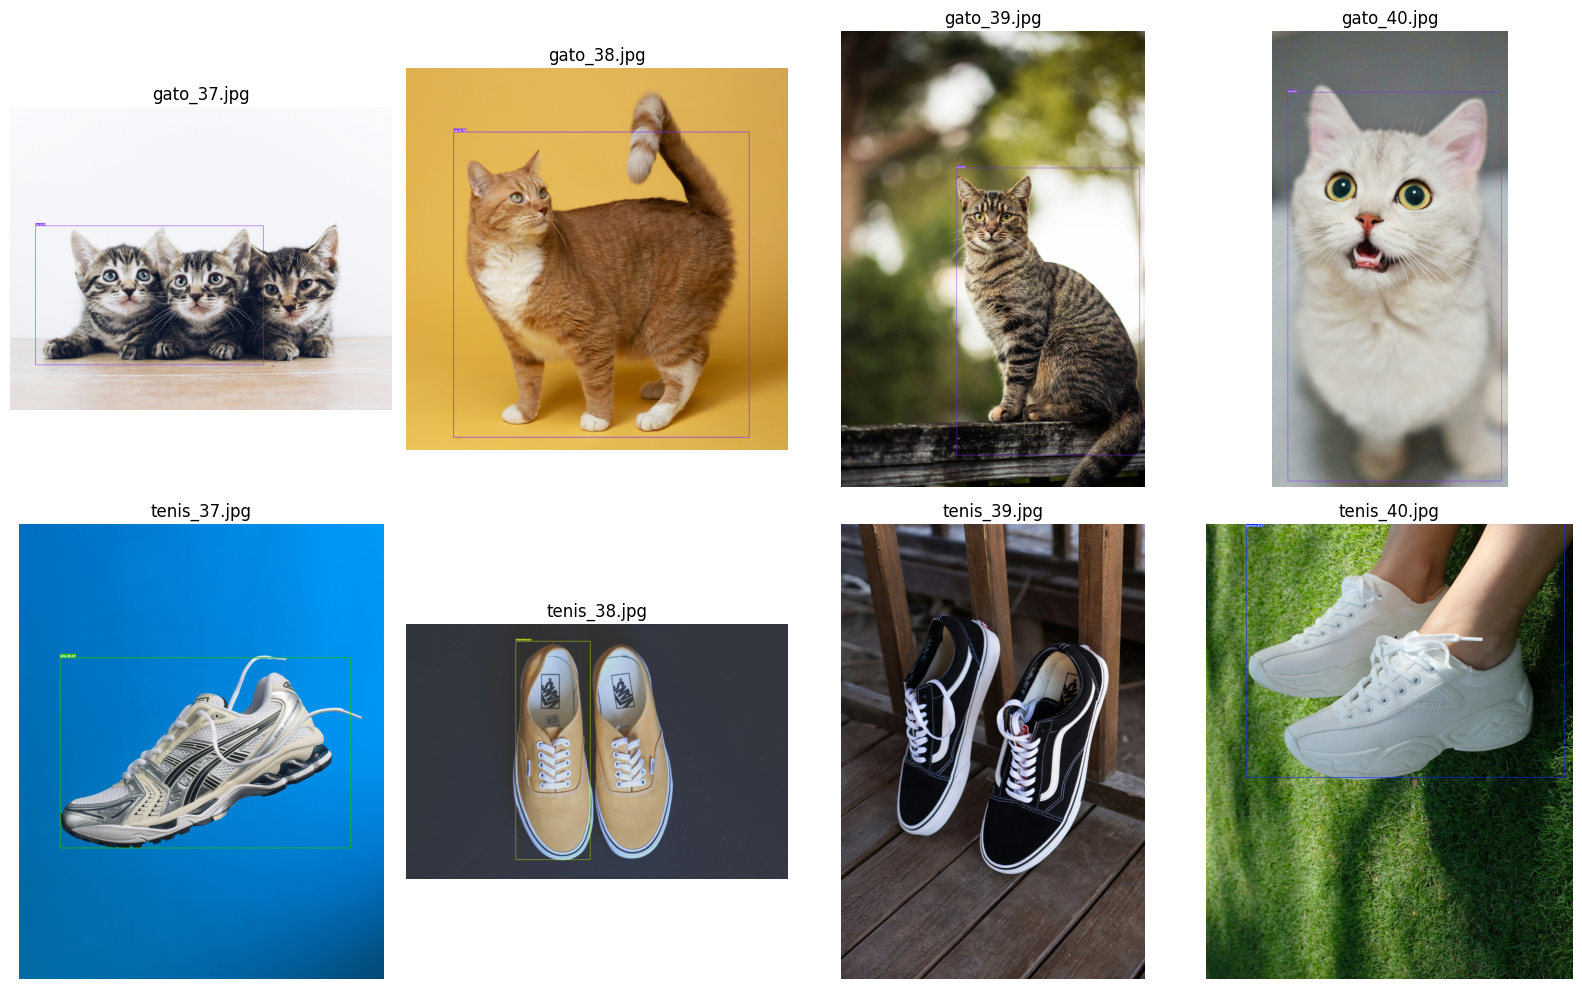

In [9]:
# Visualizar os resultados da YOLOv5 padrão

import glob
import matplotlib.pyplot as plt
from PIL import Image
import os

resultado_path = "/content/yolov5/runs/detect/yolo_padrao"

imagens = sorted(glob.glob(f"{resultado_path}/*"))

plt.figure(figsize=(16, 10))

for i, caminho in enumerate(imagens):
    imagem = Image.open(caminho)

    plt.subplot(2, 4, i + 1)
    plt.imshow(imagem)
    plt.title(os.path.basename(caminho))
    plt.axis("off")

plt.tight_layout()
plt.show()

### Análise visual das detecções

A visualização das bounding boxes confirma os resultados apresentados pela
saída do modelo. A YOLOv5 padrão localizou corretamente os gatos, enquanto
as imagens de tênis apresentaram classificações incorretas ou ausência de
detecção.

A diferença evidencia visualmente o comportamento de um modelo pré-treinado
quando aplicado a classes que não são reconhecidas adequadamente pelos seus
pesos originais.

## CNN treinada do zero

Nesta etapa será desenvolvida uma Rede Neural Convolucional (CNN) para
classificar as imagens do dataset entre as classes `gato` e `tenis`.

Diferentemente da YOLOv5, utilizada para detecção de objetos, a CNN será
utilizada para classificação de imagens. Portanto, seu objetivo será
determinar a qual das duas classes cada imagem pertence, sem localizar o
objeto por meio de bounding boxes.

A rede será construída e treinada do zero, sem utilizar pesos pré-treinados.
Serão utilizadas as imagens do mesmo dataset empregado nas etapas anteriores,
permitindo posteriormente comparar seu desempenho com as abordagens YOLO.

In [10]:
# Inspecionar as imagens de treino, validação e teste

import os

dataset_path = "/content/dataset"

for conjunto in ["train", "val", "test"]:
    images_path = os.path.join(dataset_path, conjunto, "images")
    imagens = sorted(os.listdir(images_path))

    print(f"\n{conjunto.upper()} - {len(imagens)} imagens")
    print(imagens)


TRAIN - 64 imagens
['gato_01.jpg', 'gato_02.jpg', 'gato_03.jpg', 'gato_04.jpg', 'gato_05.jpg', 'gato_06.jpg', 'gato_07.jpg', 'gato_08.jpg', 'gato_09.jpg', 'gato_10.jpg', 'gato_11.jpg', 'gato_12.jpg', 'gato_13.jpg', 'gato_14.jpg', 'gato_15.jpg', 'gato_16.jpg', 'gato_17.jpg', 'gato_18.jpg', 'gato_19.jpg', 'gato_20.jpg', 'gato_21.jpg', 'gato_22.jpg', 'gato_23.jpg', 'gato_24.jpg', 'gato_25.jpg', 'gato_26.jpg', 'gato_27.jpg', 'gato_28.jpg', 'gato_29.jpg', 'gato_30.jpg', 'gato_31.jpg', 'gato_32.jpg', 'tenis_01.jpg', 'tenis_02.jpg', 'tenis_03.jpg', 'tenis_04.jpg', 'tenis_05.jpg', 'tenis_06.jpg', 'tenis_07.jpg', 'tenis_08.jpg', 'tenis_09.jpg', 'tenis_10.jpg', 'tenis_11.jpg', 'tenis_12.jpg', 'tenis_13.jpg', 'tenis_14.jpg', 'tenis_15.jpg', 'tenis_16.jpg', 'tenis_17.jpg', 'tenis_18.jpg', 'tenis_19.jpg', 'tenis_20.jpg', 'tenis_21.jpg', 'tenis_22.jpg', 'tenis_23.jpg', 'tenis_24.jpg', 'tenis_25.jpg', 'tenis_26.jpg', 'tenis_27.jpg', 'tenis_28.jpg', 'tenis_29.jpg', 'tenis_30.jpg', 'tenis_31.jpg', 'te

In [11]:
# Criar estrutura do dataset para classificação com CNN

import os
import shutil

origem = "/content/dataset"
destino = "/content/dataset_cnn"

# Criar as pastas das classes
for conjunto in ["train", "val", "test"]:
    for classe in ["gato", "tenis"]:
        os.makedirs(
            os.path.join(destino, conjunto, classe),
            exist_ok=True
        )

# Copiar as imagens para suas respectivas classes
for conjunto in ["train", "val", "test"]:

    pasta_imagens = os.path.join(origem, conjunto, "images")

    for arquivo in os.listdir(pasta_imagens):

        if arquivo.startswith("gato_"):
            classe = "gato"

        elif arquivo.startswith("tenis_"):
            classe = "tenis"

        else:
            continue

        shutil.copy(
            os.path.join(pasta_imagens, arquivo),
            os.path.join(destino, conjunto, classe, arquivo)
        )

print("Dataset da CNN criado com sucesso!")

Dataset da CNN criado com sucesso!


In [13]:
# Carregar os datasets para a CNN

import tensorflow as tf

img_size = (224, 224)
batch_size = 16

train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/dataset_cnn/train",
    image_size=img_size,
    batch_size=batch_size,
    label_mode="binary",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/dataset_cnn/val",
    image_size=img_size,
    batch_size=batch_size,
    label_mode="binary",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/dataset_cnn/test",
    image_size=img_size,
    batch_size=batch_size,
    label_mode="binary",
    shuffle=False
)

Found 64 files belonging to 2 classes.
Found 8 files belonging to 2 classes.
Found 8 files belonging to 2 classes.


In [14]:
# Verificar a ordem das classes

print("Classes:", train_ds.class_names)

for indice, classe in enumerate(train_ds.class_names):
    print(f"{indice} = {classe}")

Classes: ['gato', 'tenis']
0 = gato
1 = tenis


In [15]:
# Construir a CNN do zero

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Rescaling,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

model = Sequential([

    # Normalização dos pixels
    Rescaling(1./255, input_shape=(224, 224, 3)),

    # Bloco convolucional 1
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Bloco convolucional 2
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Bloco convolucional 3
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Classificação
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),

    # Saída binária
    Dense(1, activation="sigmoid")
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [16]:
# Exibir a arquitetura da CNN

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# Compilar o modelo

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [18]:
# Configurar o Early Stopping

from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

In [19]:
# Treinamento da CNN

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[early_stopping]
)

Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.4844 - loss: 1.8156 - val_accuracy: 0.5000 - val_loss: 0.7473
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 16s 4s/step - accuracy: 0.5469 - loss: 0.7341 - val_accuracy: 0.5000 - val_loss: 0.6539
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 15s 4s/step - accuracy: 0.6406 - loss: 0.6333 - val_accuracy: 0.8750 - val_loss: 0.6327
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 21s 4s/step - accuracy: 0.8125 - loss: 0.5430 - val_accuracy: 0.6250 - val_loss: 0.5582
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 20s 4s/step - accuracy: 0.7031 - loss: 0.5554 - val_accuracy: 0.7500 - val_loss: 0.4997
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 15s 4s/step - accuracy: 0.8281 - loss: 0.3997 - val_accuracy: 0.7500 - val_loss: 0.5501
Epoch 7/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 15s 4s/step - accuracy: 0.8750 - loss: 0.2860 - val_accuracy: 0.7500 - val_loss: 0.4706
Epoch 8/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 20s 4s/step - accuracy: 0.9062 - loss: 0.2175 - val_accuracy: 0.8750 - val_loss: 0.5602
Epoch 9/

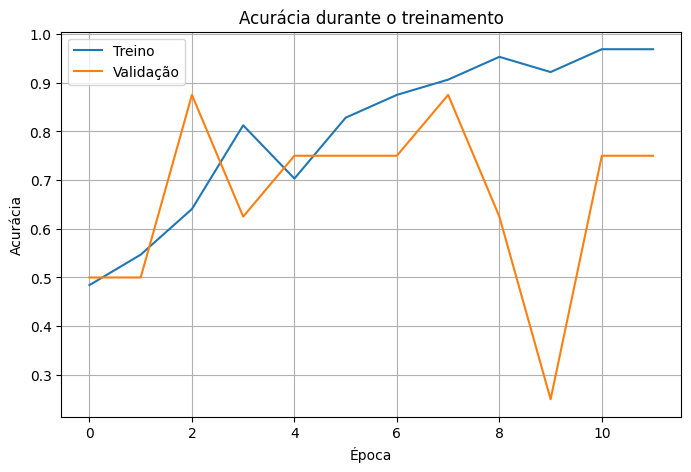

In [20]:
# Visualizar o histórico de treinamento

import matplotlib.pyplot as plt

# Acurácia
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Treino")
plt.plot(history.history["val_accuracy"], label="Validação")

plt.title("Acurácia durante o treinamento")
plt.xlabel("Época")
plt.ylabel("Acurácia")
plt.legend()
plt.grid()

plt.show()

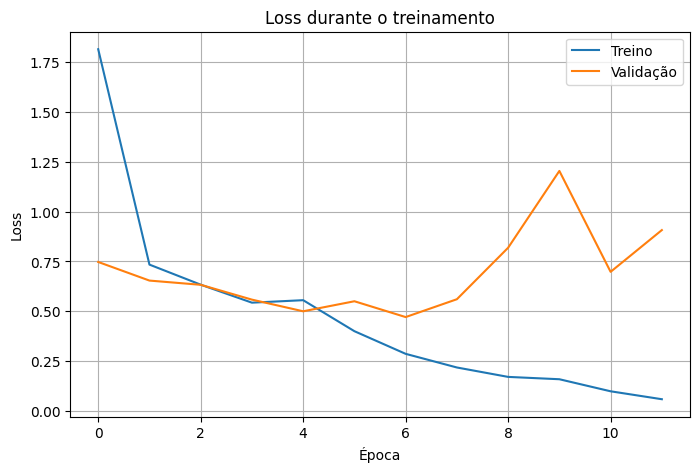

In [21]:
# Visualizar a perda durante o treinamento

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Treino")
plt.plot(history.history["val_loss"], label="Validação")

plt.title("Loss durante o treinamento")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()

### Análise do treinamento da CNN

A CNN foi configurada com um limite máximo de 50 épocas e Early Stopping
com paciência de 5 épocas, monitorando a perda de validação (`val_loss`).

O treinamento foi interrompido automaticamente na época 12, sendo
restaurados os pesos da época 7, que apresentou a melhor perda de validação.

Ao analisar os gráficos, observa-se que a acurácia de treinamento aumentou
progressivamente, enquanto a perda de treinamento diminuiu de forma
consistente. Entretanto, as métricas de validação apresentaram maiores
oscilações.

Esse comportamento indica sinais de overfitting, pois o modelo continuou
melhorando no conjunto de treinamento sem apresentar a mesma evolução no
conjunto de validação.

Também deve ser considerado que o conjunto de validação possui apenas
8 imagens. Dessa forma, cada imagem corresponde a 12,5% da acurácia de
validação, fazendo com que poucos erros ou acertos provoquem grandes
variações nessa métrica.

O uso do Early Stopping foi importante para interromper o treinamento e
restaurar os pesos do momento em que o modelo apresentou melhor desempenho
em relação à perda de validação.

In [22]:
# Avaliar a CNN no conjunto de teste

test_loss, test_accuracy = model.evaluate(test_ds)

print(f"\nLoss no teste: {test_loss:.4f}")
print(f"Acurácia no teste: {test_accuracy:.4f}")
print(f"Acurácia no teste: {test_accuracy * 100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.6250 - loss: 0.6326

Loss no teste: 0.6326
Acurácia no teste: 0.6250
Acurácia no teste: 62.50%


In [23]:
# Realizar previsões nas imagens de teste

import numpy as np

y_prob = model.predict(test_ds).flatten()

# Converter probabilidades em classes
y_pred = (y_prob >= 0.5).astype(int)

# Recuperar as classes verdadeiras
y_true = np.concatenate([
    labels.numpy().flatten()
    for images, labels in test_ds
]).astype(int)

# Nomes das classes
classes = ["gato", "tenis"]

print("Resultados das previsões:\n")

for i in range(len(y_true)):
    real = classes[y_true[i]]
    previsto = classes[y_pred[i]]

    resultado = "CORRETO" if y_true[i] == y_pred[i] else "INCORRETO"

    print(
        f"Imagem {i + 1}: "
        f"Real = {real} | "
        f"Previsto = {previsto} | "
        f"Probabilidade = {y_prob[i]:.4f} | "
        f"{resultado}"
    )

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Resultados das previsões:

Imagem 1: Real = gato | Previsto = gato | Probabilidade = 0.3372 | CORRETO
Imagem 2: Real = gato | Previsto = gato | Probabilidade = 0.2178 | CORRETO
Imagem 3: Real = gato | Previsto = gato | Probabilidade = 0.0523 | CORRETO
Imagem 4: Real = gato | Previsto = gato | Probabilidade = 0.2811 | CORRETO
Imagem 5: Real = tenis | Previsto = gato | Probabilidade = 0.4316 | INCORRETO
Imagem 6: Real = tenis | Previsto = gato | Probabilidade = 0.1529 | INCORRETO
Imagem 7: Real = tenis | Previsto = tenis | Probabilidade = 0.9960 | CORRETO
Imagem 8: Real = tenis | Previsto = gato | Probabilidade = 0.2730 | INCORRETO


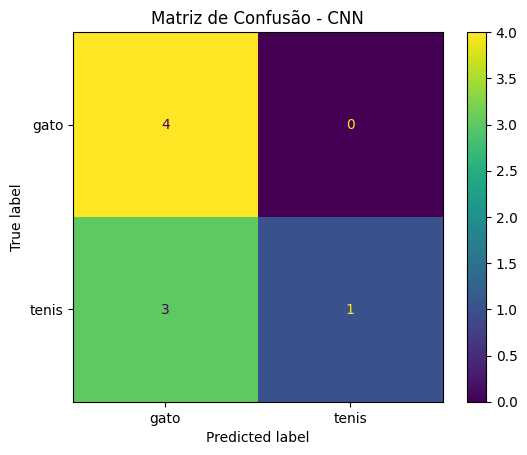

In [24]:
# Matriz de confusão da CNN

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["gato", "tenis"]
)

disp.plot()

plt.title("Matriz de Confusão - CNN")
plt.show()

### Avaliação da CNN no conjunto de teste

A CNN apresentou acurácia de **62,50%** no conjunto de teste, correspondendo
a 5 classificações corretas entre as 8 imagens avaliadas.

A matriz de confusão mostra diferenças importantes entre as duas classes.
Todas as 4 imagens de gatos foram classificadas corretamente. Entretanto,
das 4 imagens de tênis, apenas 1 foi classificada corretamente, enquanto
3 foram classificadas incorretamente como gato.

Como o conjunto de treinamento é balanceado, contendo 32 imagens de cada
classe, essa diferença não está relacionada a um desbalanceamento na
quantidade de exemplos utilizados no treinamento.

Os resultados sugerem dificuldade de generalização da CNN para diferentes
imagens de tênis. Além disso, durante o treinamento foram observados sinais
de overfitting, com melhora contínua das métricas de treino sem a mesma
estabilidade nas métricas de validação.

Deve-se considerar também o tamanho reduzido do dataset. A CNN foi treinada
do zero utilizando apenas 64 imagens de treinamento, enquanto o conjunto
de teste possui somente 8 imagens. Portanto, os resultados representam o
comportamento do modelo neste experimento e não devem ser generalizados
para conjuntos de dados maiores.

In [25]:
# Medir o tempo médio de inferência da CNN

import time
import numpy as np

# Obter apenas as imagens do conjunto de teste
test_images = np.concatenate([
    images.numpy()
    for images, labels in test_ds
])

# Aquecimento da GPU
_ = model.predict(test_images, verbose=0)

# Medir a inferência
inicio = time.perf_counter()

_ = model.predict(test_images, verbose=0)

fim = time.perf_counter()

tempo_total = fim - inicio
tempo_medio = tempo_total / len(test_images)

print(f"Quantidade de imagens: {len(test_images)}")
print(f"Tempo total de inferência: {tempo_total:.4f} s")
print(f"Tempo médio por imagem: {tempo_medio * 1000:.2f} ms")

Quantidade de imagens: 8
Tempo total de inferência: 0.2358 s
Tempo médio por imagem: 29.48 ms


### Tempo de inferência da CNN

A CNN apresentou tempo total de inferência de aproximadamente **0,2358 s**
para as 8 imagens do conjunto de teste, correspondendo a um tempo médio de
aproximadamente **29,48 ms por imagem**, utilizando uma GPU Tesla T4.

No mesmo ambiente, a YOLOv5 padrão apresentou aproximadamente **29,4 ms de
inferência por imagem**.

Os valores foram semelhantes neste experimento. Entretanto, essa comparação
deve ser interpretada com cautela, pois os modelos possuem objetivos e
arquiteturas diferentes e os tempos foram obtidos por procedimentos de
execução distintos.

O tempo de inferência representa apenas um dos critérios de comparação entre
as abordagens e deve ser analisado juntamente com o processo de treinamento,
a facilidade de uso e os resultados obtidos por cada modelo.

## Resultados da YOLOv5 adaptável — Entrega 1

Na Entrega 1, a YOLOv5 foi customizada utilizando o dataset próprio com
80 imagens das classes `gato` e `tenis`.

Foram realizados diferentes experimentos de treinamento. Para a comparação
desta entrega, será considerado o modelo treinado com **Early Stopping**,
que interrompeu o treinamento após 50 épocas.

Os resultados obtidos foram:

- **Precision:** 0,870
- **Recall:** 0,884
- **mAP\@0.5:** 0,928
- **mAP\@0.5:0.95:** 0,557
- **Épocas executadas:** 50
- **Tempo de treinamento:** 0,931 h (aproximadamente 55,9 minutos)

Essas métricas correspondem a uma tarefa de detecção de objetos e, portanto,
não devem ser comparadas diretamente com a acurácia obtida pela CNN, que
realiza classificação de imagens.

A principal diferença em relação à YOLOv5 padrão é que a versão adaptável
foi treinada especificamente para reconhecer as classes utilizadas neste
projeto, enquanto a YOLO padrão utilizou diretamente seus pesos
pré-treinados, sem treinamento adicional.

## Comparação das abordagens

As três abordagens utilizadas possuem características e objetivos diferentes.
Por esse motivo, seus resultados não devem ser comparados apenas por um único
valor numérico.

| Critério | YOLOv5 Adaptável | YOLOv5 Padrão | CNN do Zero |
|---|---|---|---|
| Abordagem | Detecção customizada | Detecção com pesos pré-treinados | Classificação de imagens |
| Classes do projeto | gato e tenis | Classes genéricas pré-treinadas | gato e tenis |
| Treinamento próprio | Sim | Não | Sim |
| Dataset próprio no treinamento | 64 treino + 8 validação | Não utilizado para treinamento | 64 treino + 8 validação |
| Resultado principal | Precision 0,870 / Recall 0,884 / mAP\@0.5 0,928 | Reconheceu os gatos, mas não reconheceu corretamente os tênis | Acurácia de teste 62,50% |
| Treinamento/customização | 50 épocas — 0,931 h (~55,9 min) | Não houve treinamento com o dataset do projeto | Early Stopping na época 12, restaurando os pesos da época 7 |
| Modelo utilizado | Pesos obtidos com Early Stopping | Pesos pré-treinados `yolov5s.pt` | Pesos restaurados da época 7 |
| Inferência | 39,7 ms/imagem | 29,4 ms/imagem | 29,48 ms/imagem |
| Customização | Treinada para `gato` e `tenis` | Sem customização | Arquitetura e treinamento próprios |
| Facilidade de uso | Exige preparação, rotulagem e treinamento | Alta, pois utiliza modelo pronto | Exige preparação dos dados, construção e treinamento da rede |

### Interpretação da comparação

A **YOLOv5 padrão** apresentou a implementação mais simples, pois não exigiu treinamento com o dataset do projeto. Os pesos pré-treinados foram utilizados diretamente para realizar as detecções. O modelo reconheceu corretamente os gatos, mas apresentou classificações incorretas ou ausência de detecção nas imagens de tênis. Esse comportamento demonstra uma limitação do uso direto de um modelo genérico quando suas classes pré-treinadas não representam adequadamente os objetos de interesse.

A **YOLOv5 adaptável** exigiu maior preparação, incluindo rotulagem das imagens, configuração do dataset e treinamento. Esse processo permitiu adaptar o modelo especificamente às classes `gato` e `tenis`. No experimento com Early Stopping foram obtidos Precision de 0,870, Recall de 0,884 e mAP\@0.5 de 0,928, com 50 épocas executadas e aproximadamente 0,931 hora de treinamento.

A **CNN treinada do zero** exigiu a definição da arquitetura e o treinamento de seus parâmetros sem utilização de pesos pré-treinados. O Early Stopping interrompeu o treinamento na época 12 e restaurou os pesos da época 7. No conjunto de teste, a CNN apresentou acurácia de 62,50%, correspondendo a 5 acertos em 8 imagens. As curvas de treinamento e validação também apresentaram sinais de overfitting, evidenciando as limitações de generalização com um conjunto reduzido de imagens.

Em relação à inferência, foram registrados aproximadamente **39,7 ms por imagem para a YOLOv5 adaptável**, **29,4 ms para a YOLOv5 padrão** e **29,48 ms para a CNN**. Neste experimento, a YOLOv5 padrão e a CNN apresentaram tempos semelhantes, enquanto a YOLOv5 adaptável apresentou um tempo maior. Esses valores devem ser interpretados com cautela, considerando as condições de execução e as diferenças entre as tarefas realizadas pelos modelos.

Por fim, as métricas utilizadas não são diretamente equivalentes. A YOLO realiza **detecção de objetos**, sendo avaliada por métricas como Precision, Recall e mAP, enquanto a CNN desenvolvida realiza **classificação da imagem completa**, sendo avaliada principalmente por acurácia e matriz de confusão. Dessa forma, a comparação deve considerar não apenas os valores numéricos, mas também a finalidade e o funcionamento de cada abordagem.

## Conclusão

Os experimentos realizados permitiram compreender, na prática, três formas diferentes de aplicar Visão Computacional: utilizar um modelo pré-treinado diretamente, adaptar um modelo existente para classes específicas e construir uma rede neural do zero.

A utilização da **YOLOv5 padrão** mostrou a praticidade de um modelo pré-treinado, que pode realizar detecções sem necessidade de um novo treinamento. Entretanto, os resultados também demonstraram que essa facilidade depende da compatibilidade entre as classes conhecidas pelo modelo e os objetos presentes no problema.

A **YOLOv5 adaptável** demonstrou a importância da customização quando o objetivo é trabalhar com classes específicas. Embora essa abordagem exija preparação do dataset, rotulagem e treinamento, ela permite direcionar o modelo para os objetos de interesse do projeto.

A **CNN treinada do zero**, por sua vez, permitiu acompanhar todo o processo de construção e treinamento de uma rede neural para classificação de imagens. O experimento também evidenciou a importância da quantidade e variedade dos dados, além de técnicas como Early Stopping para interromper o treinamento
quando não há melhora na validação e reduzir o risco de overfitting.

Assim, os resultados mostraram que a escolha de uma abordagem de Visão Computacional depende do objetivo da aplicação, das classes que precisam ser reconhecidas, da disponibilidade de dados e da necessidade de customização. Mais do que comparar apenas os valores das métricas, os experimentos permitiram compreender as diferenças entre utilizar um modelo pronto, adaptar um modelo pré-treinado e desenvolver uma rede neural do zero.